# Q3 - Fitness based Copy Mutate

Here we improve the Q2 algorithm by giving every ingredient a fitness value based on how popular it is in the real cuisine. When an ingredient is replaced only a fitter one is allowed to come in. Then we compare recipe size and frequency rank with Q1, Q2 and the real data.

In [1]:
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DATA_PATH   = "Q1b_NER.csv"
NR0         = 200
N_INSTANCES = 5
SEEDS       = [11, 22, 33, 44, 55]
MAX_TRIES   = 10_000

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

In [2]:
df = pd.read_csv(DATA_PATH)
df["Ingredient_Name"] = df["Ingredient_Name"].astype(str).str.strip().str.lower()
df = df[~df["Ingredient_Name"].isin(["", "nan"])]

real_recipes = [frozenset(g) for _, g in df.groupby("Recipe_ID")["Ingredient_Name"]]
real_recipes = [r for r in real_recipes if len(r) > 0]

N_R           = len(real_recipes)
nature_basket = sorted(set().union(*real_recipes))
N_I           = len(nature_basket)
real_sizes    = np.array([len(r) for r in real_recipes])
S             = int(round(real_sizes.mean()))
MAX_SIZE      = int(real_sizes.max())

N_EPOCHS          = int(round(N_R / NR0))
RECIPES_PER_EPOCH = int(round(N_R / N_EPOCHS))
PHI = N_I / N_R
KB0 = max(S + 1, int(round(PHI * NR0)))

print(f"Recipes (N_R)              : {N_R}")
print(f"Nature Basket size (N_I)   : {N_I}")
print(f"Recipe size s (mean, round): {S}   (mean={real_sizes.mean():.2f}, std={real_sizes.std():.2f})")
print(f"Epochs = round({N_R}/{NR0}) = round({N_R/NR0:.2f}) = {N_EPOCHS}")
print(f"Recipes per epoch = round({N_R}/{N_EPOCHS}) = round({N_R/N_EPOCHS:.2f}) = {RECIPES_PER_EPOCH}")
print(f"Primordial recipes NR(t=0) : {NR0}")
print(f"Initial Kitchen Basket     : {KB0}   (KB/NB ratio = {KB0/N_I:.4f})")

Recipes (N_R)              : 9988
Nature Basket size (N_I)   : 12641
Recipe size s (mean, round): 10   (mean=10.00, std=4.20)
Epochs = round(9988/200) = round(49.94) = 50
Recipes per epoch = round(9988/50) = round(199.76) = 200
Primordial recipes NR(t=0) : 200
Initial Kitchen Basket     : 253   (KB/NB ratio = 0.0200)


In [3]:
def size_distribution(recipes, max_size):
    """P(size): fraction of recipes having each size 0..max_size."""
    sizes = np.array([len(r) for r in recipes])
    counts = np.bincount(sizes, minlength=max_size + 1)[: max_size + 1]
    return counts / counts.sum(), sizes

def frequency_rank(recipes):
    """Normalised frequency f(r) = (#recipes containing rank-r ingredient) / (#recipes), sorted by rank."""
    c = Counter(ing for r in recipes for ing in r)
    return np.array(sorted(c.values(), reverse=True), dtype=float) / len(recipes)

def stack_ragged(arrays):
    """Pad 1-D arrays of different lengths with NaN so mean/std can be taken across instances."""
    L = max(len(a) for a in arrays)
    out = np.full((len(arrays), L), np.nan)
    for i, a in enumerate(arrays):
        out[i, : len(a)] = a
    return out

def label_log_axes(ax):
    """Label log-scale ticks at 1, 2 and 5 of every decade with plain numbers."""
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:g}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(mticker.LogLocator(base=10, numticks=15))
        axis.set_minor_locator(mticker.LogLocator(base=10, subs=(2, 5), numticks=15))
        axis.set_major_formatter(fmt)
        axis.set_minor_formatter(fmt)
    ax.tick_params(axis="both", which="minor", labelsize=8)

def plot_size_distribution(results, title, fname):
    """Recipe-size distribution across instances (mean ± std bars), with overall mean and ±1 std marked."""
    max_size = max(MAX_SIZE, max(len(r) for res in results for r in res))
    P = np.array([size_distribution(res, max_size)[0] for res in results])
    all_sizes = np.concatenate([size_distribution(res, max_size)[1] for res in results])
    mu, sd = all_sizes.mean(), all_sizes.std()
    P_real, _ = size_distribution(real_recipes, max_size)
    x = np.arange(max_size + 1)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.bar(x, P.mean(0), yerr=P.std(0), capsize=3, color="tab:blue", alpha=0.75,
           label=f"Model (mean ± std over {len(results)} instances)")
    ax.plot(x, P_real, "o--", color="tab:red", ms=4, label="Real cuisine")
    ax.axvline(mu, color="k", lw=2, label=f"Model mean = {mu:.2f}")
    ax.axvspan(mu - sd, mu + sd, color="grey", alpha=0.2, label=f"Model mean ± std ({sd:.2f})")
    ax.set_xlabel("Recipe size, s (number of ingredients)")
    ax.set_ylabel("P(s)  (fraction of recipes)")
    ax.set_title(title)
    ax.set_xticks(x[:: 2 if max_size > 20 else 1])
    ax.set_xlim(0.5, max_size + 0.5)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname} | model size mean = {mu:.2f}, std = {sd:.2f} | "
          f"real mean = {real_sizes.mean():.2f}, std = {real_sizes.std():.2f}")

def plot_frequency_rank(results, title, fname):
    """Normalised frequency-rank distribution (log-log), mean ± std across instances vs real cuisine."""
    F = stack_ragged([frequency_rank(res) for res in results])
    mean, std = np.nanmean(F, 0), np.nanstd(F, 0)
    ranks = np.arange(1, F.shape[1] + 1)
    f_real = frequency_rank(real_recipes)

    fig, ax = plt.subplots(figsize=(9, 6))
    for i, row in enumerate(F):
        ax.plot(ranks, row, lw=0.6, alpha=0.4, label="Individual instances" if i == 0 else None)
    ax.plot(ranks, mean, color="tab:blue", lw=2, label=f"Model mean ({len(results)} instances)")
    ax.fill_between(ranks, np.clip(mean - std, 1e-6, None), mean + std,
                    color="tab:blue", alpha=0.25, label="Model mean ± std")
    ax.plot(np.arange(1, len(f_real) + 1), f_real, color="tab:red", lw=2, ls="--", label="Real cuisine")
    ax.set_xscale("log"); ax.set_yscale("log"); label_log_axes(ax)
    ax.set_xlabel("Rank, r (log scale)")
    ax.set_ylabel("Normalised frequency, f(r) = n(r) / N_R (log scale)")
    ax.set_title(title)
    ax.legend(); ax.grid(which="both", alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname}")

def summarise(results, label):
    """Key numbers of a set of runs vs the real cuisine (used in the observations)."""
    sizes = np.concatenate([[len(r) for r in res] for res in results])
    f1    = [frequency_rank(res)[0] for res in results]
    used  = [len(set().union(*res)) for res in results]
    f_real = frequency_rank(real_recipes)
    print(f"{label}")
    print(f"  recipe size        : mean = {sizes.mean():.2f}, std = {sizes.std():.2f}   "
          f"(real: {real_sizes.mean():.2f}, {real_sizes.std():.2f})")
    print(f"  f(1) top ingredient: {np.mean(f1):.3f} ± {np.std(f1):.3f}   (real: {f_real[0]:.3f})")
    print(f"  ingredients used   : {np.mean(used):.0f} ± {np.std(used):.0f}   (real: {len(f_real)})")

## Fitness of ingredients

Each ingredient in the nature basket gets fitness equal to the number of recipes it is in, in the real data. So garlic with 3104 recipes is the fittest, then olive oil (2141) and butter (1817) and so on. About two-thirds of the ingredients (8571 out of 12641) appear only once so a lot of them have same fitness, to break these ties we add a small random number between 0 and 1. Since its less than 1 it never changes the order between ingredients with different popularity.

In [4]:
ing_freq = Counter(ing for r in real_recipes for ing in r)
_fit_rng = random.Random(0)
FITNESS = {ing: ing_freq[ing] + _fit_rng.random() for ing in nature_basket}
print("Top-10 fittest ingredients:")
for ing in sorted(FITNESS, key=FITNESS.get, reverse=True)[:10]:
    print(f"  {ing:30s} popularity = {ing_freq[ing]}")

Top-10 fittest ingredients:
  garlic                         popularity = 3104
  olive oil                      popularity = 2141
  butter                         popularity = 1817
  plain flour                    popularity = 1643
  eggs                           popularity = 1589
  lemon                          popularity = 1357
  onion                          popularity = 1152
  golden caster sugar            popularity = 962
  caster sugar                   popularity = 942
  vegetable oil                  popularity = 882


## Fitness based algorithm

This is same as Q2 with modify, add and delete each at 1/3 and size limits of 2 and 33, but two things are changed. In modification we pick a random ingredient from the recipe and a random one from KB and only replace if the KB one is fitter, if not we try again, so every replacement brings in a more popular ingredient. In addition the new ingredient is picked from KB with probability proportional to its fitness so popular ones get added more often. Deletion is same as Q2. kb_cum keeps a running total of fitness so that the weighted pick is fast.

In [5]:
P_MODIFY, P_ADD, P_DELETE = 1/3, 1/3, 1/3
MIN_SIZE = 2
op_counts = Counter()

def grow_kitchen(kb_list, kb_set, kb_cum, target_size, nb_pool):
    """Add NB ingredients to KB; also keep cumulative fitness for fitness-weighted sampling."""
    while len(kb_list) < target_size and nb_pool:
        ing = nb_pool.pop()
        kb_list.append(ing); kb_set.add(ing)
        kb_cum.append((kb_cum[-1] if kb_cum else 0.0) + FITNESS[ing])

def init_primordial(kb_list, rng):
    """Primordial cuisine: NR0 unique recipes, each with S random ingredients from KB."""
    cuisine_list, cuisine_set = [], set()
    while len(cuisine_list) < NR0:
        r = frozenset(rng.sample(kb_list, S))
        if r not in cuisine_set:
            cuisine_list.append(r); cuisine_set.add(r)
    return cuisine_list, cuisine_set

def modify_fitter(rec, kb_list, rng):
    """REPLACEMENT WITH FITNESS: pick a random recipe ingredient and a random KB ingredient;
    replace only if the KB ingredient is FITTER (more popular). Repeat until modified."""
    for _ in range(MAX_TRIES):
        i = rng.randrange(len(rec))
        new = kb_list[rng.randrange(len(kb_list))]
        if new not in rec and FITNESS[new] > FITNESS[rec[i]]:
            rec[i] = new
            return rec
    return None

def add_fitness_weighted(rec, kb_list, kb_cum, rng):
    """ADDITION: choose a KB ingredient with probability proportional to its fitness."""
    if len(rec) >= MAX_SIZE:
        return None
    for _ in range(MAX_TRIES):
        new = rng.choices(kb_list, cum_weights=kb_cum)[0]
        if new not in rec:
            rec.append(new)
            return rec
    return None

def delete(rec, rng):
    """DELETION: remove a random ingredient from the recipe."""
    if len(rec) <= MIN_SIZE:
        return None
    rec.pop(rng.randrange(len(rec)))
    return rec

def mutate(recipe, kb_list, kb_cum, rng):
    """Choose one mutation type and apply it to a copy of the recipe."""
    op = rng.choices(["modify", "add", "delete"], weights=[P_MODIFY, P_ADD, P_DELETE])[0]
    rec = sorted(recipe)
    if op == "modify":
        out = modify_fitter(rec, kb_list, rng)
    elif op == "add":
        out = add_fitness_weighted(rec, kb_list, kb_cum, rng)
    else:
        out = delete(rec, rng)
    return (frozenset(out), op) if out is not None else (None, op)

def evolve_cuisine(seed):
    """Run one instance of fitness-driven cuisine evolution and return the final cuisine."""
    rng = random.Random(seed)
    nb_pool = nature_basket[:]; rng.shuffle(nb_pool)
    kb_list, kb_set, kb_cum = [], set(), []
    grow_kitchen(kb_list, kb_set, kb_cum, KB0, nb_pool)
    cuisine_list, cuisine_set = init_primordial(kb_list, rng)

    for epoch in range(1, N_EPOCHS):
        target = N_R if epoch == N_EPOCHS - 1 else min(N_R, NR0 + epoch * RECIPES_PER_EPOCH)
        grow_kitchen(kb_list, kb_set, kb_cum, int(round(PHI * target)), nb_pool)
        while len(cuisine_list) < target:
            parent = cuisine_list[rng.randrange(len(cuisine_list))]
            child, op = mutate(parent, kb_list, kb_cum, rng)
            if child is not None and child not in cuisine_set:
                cuisine_list.append(child); cuisine_set.add(child)
                op_counts[op] += 1
    return cuisine_list

## Running 5 instances

Same 5 seeds as before, here we also print the top 5 ingredients for each run.

In [6]:
results = []
for k, seed in enumerate(SEEDS[:N_INSTANCES], 1):
    cuisine = evolve_cuisine(seed)
    results.append(cuisine)
    sz = np.array([len(r) for r in cuisine])
    top = Counter(i for r in cuisine for i in r).most_common(5)
    print(f"Instance {k} (seed={seed}): {len(cuisine)} recipes | size mean={sz.mean():.2f}, "
          f"std={sz.std():.2f} | top-5: {[t[0] for t in top]}")
print("Accepted mutations by type (all instances):", dict(op_counts))

Instance 1 (seed=11): 9988 recipes | size mean=9.95, std=1.56 | top-5: ['dessert apples', 'vegetable oil', 'fresh  thyme leaf', 'double cream or full-fat crème fraîche', 'buttermilk']
Instance 2 (seed=22): 9988 recipes | size mean=10.02, std=1.59 | top-5: ['garlic', 'cheese tortilla chips', 'msg', 'dried chili fine korean chili powder', 'fine sev or bombay mix']
Instance 3 (seed=33): 9988 recipes | size mean=10.08, std=1.59 | top-5: ['garlic', 'sweet potato fries', 'pea', 'taco seasoning', 'passion fruit seeds']
Instance 4 (seed=44): 9988 recipes | size mean=9.95, std=1.62 | top-5: ['lemon wedges', 'gel food colourings', 'milk', 'coconut shavings', 'tortilla chips soured cream']
Instance 5 (seed=55): 9988 recipes | size mean=10.05, std=1.59 | top-5: ['plain flour', 'date molasses', 'red lentils', 'rice poppadums', 'lime wedges']
Accepted mutations by type (all instances): {'add': 16567, 'modify': 16574, 'delete': 15799}


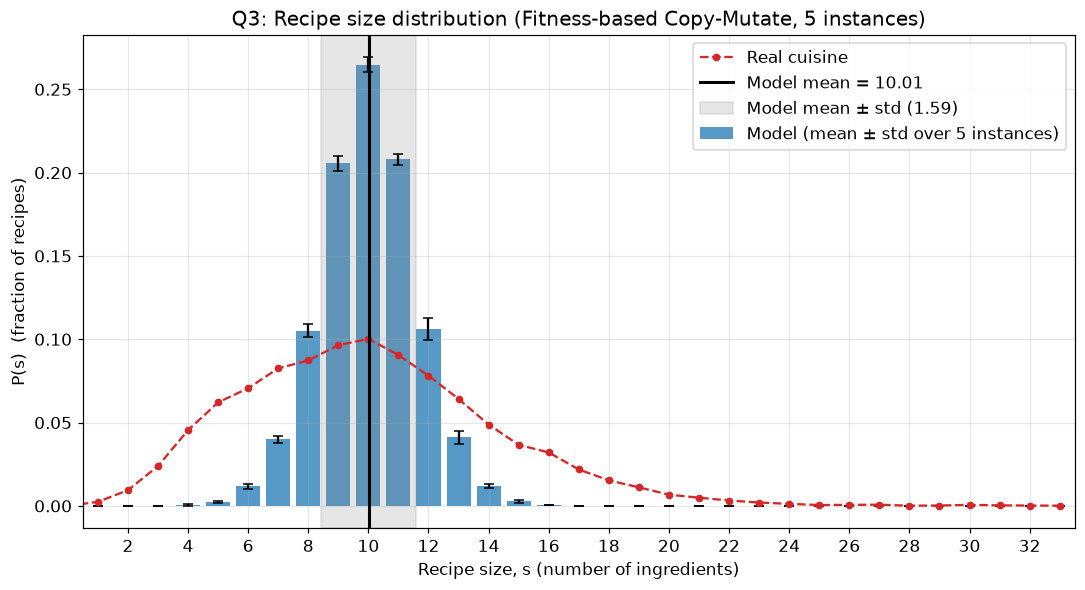

Saved Q3_Recipe_Size_Distribution.png | model size mean = 10.01, std = 1.59 | real mean = 10.00, std = 4.20


In [7]:
plot_size_distribution(results, "Q3: Recipe size distribution (Fitness-based Copy-Mutate, 5 instances)",
                       "Q3_Recipe_Size_Distribution.png")

## Recipe size observations

Mean is 10.01 and std is 1.59 which is almost same as Q2. This makes sense because fitness only decides which ingredient is used and not how many, so size distribution doesnt change and its still narrower then the real one (4.20).

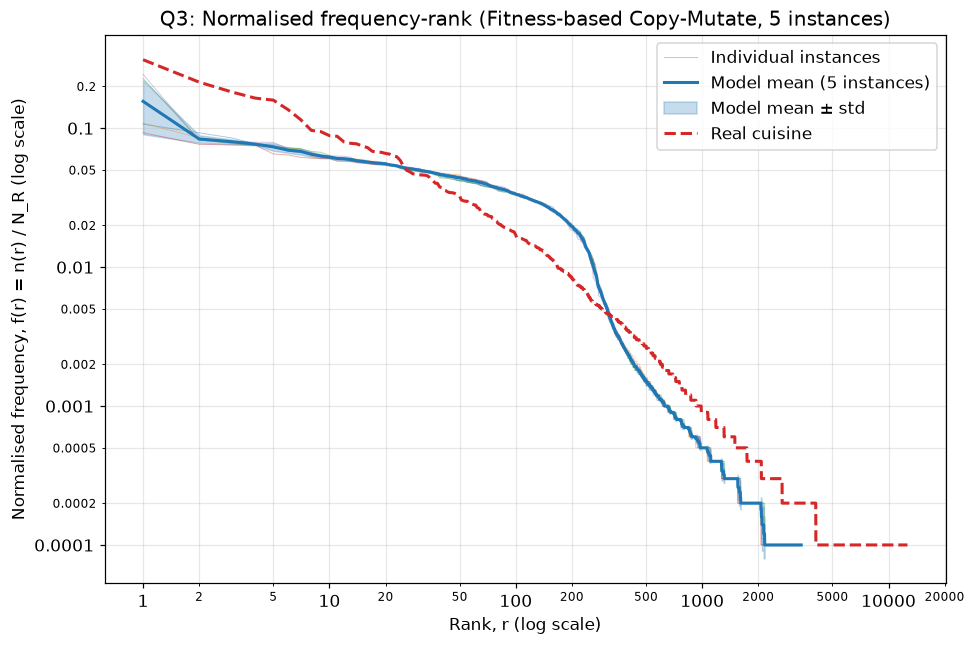

Saved Q3_Frequency_Rank_Distribution.png


In [8]:
plot_frequency_rank(results, "Q3: Normalised frequency-rank (Fitness-based Copy-Mutate, 5 instances)",
                    "Q3_Frequency_Rank_Distribution.png")

## Frequency rank observations

f(1) is now 0.156 which is about double of Q1 and Q2, so the top of the curve is steeper and closer to the real value of 0.311. The model uses only 3348 ingredients now because popular ingredients keep replacing the less popular ones. The std between runs is bigger at the top ranks since the top ingredient changes from run to run, garlic is on top in 2 of the 5 runs but in others its dessert apples, lemon wedges or plain flour. This happens because ingredients enter the kitchen in random order, so if a very popular one comes in late it gets less time to spread while early ones get copied more. The drop near rank 250 is still there for the same reason as Q1.

## Conclusion

Comparing the three models, Q1 only gets the mean size right since all recipes have size 10. Q2 gives a spread of sizes (std 1.62) but its still less than real (4.20), and Q3 gives almost the same sizes as Q2 (std 1.59). For frequency rank the top ingredient frequency is 0.077 in Q1, 0.083 in Q2 and 0.156 in Q3 compared to 0.311 in the real cuisine, so adding fitness is what makes the model closer to real data. The number of ingredients used goes down from 5646 to 4478 to 3348 as the models get more selective, while the real cuisine has 12641.

None of the models fully matches the real data. Real recipes vary much more in size, the NER data has many names for the same ingredient which makes the real tail very long, and the random order in which ingredients enter the kitchen gives early ingredients an extra advantage. Some ways to improve it would be to add ingredients to the kitchen based on popularity, or do more then one mutation per copy to get a wider size distribution.

In [9]:
summarise(results, "Q3")

Q3
  recipe size        : mean = 10.01, std = 1.59   (real: 10.00, 4.20)
  f(1) top ingredient: 0.156 ± 0.066   (real: 0.311)
  ingredients used   : 3348 ± 40   (real: 12641)
